<a href="https://colab.research.google.com/github/erickcorrea3092/antiMBT_QSAR_model/blob/main/3_Dionisio_QSAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Código creado por el Dr. Erick Correa Padilla

FES Zaragoza UNAM.


Este código está para ayudarte a predecir propiedades de nuevas sustancias, úsalo con cuidado.



Avertencia
Por cuestiones de actualización de numpy es necesario correr la primer celda, una vez que haya terminado de ejecutar es necesario reiniciar sesion (ctrl+ M.) y posteriormente ejecutar a partir de la segunda celda en adelante, la primer celda ya no se debe ejecutar

# ANTECEDENTES

Imports variables globales y clases auxiliares.

In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
a= False
if a== True:
  with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install --upgrade --force-reinstall numpy
      pbar.update(33)
      !pip install --upgrade --force-reinstall pandas
      pbar.update(33)
      !pip install --upgrade --force-reinstall mordredcommunity
      ! pip install dash==3.2.0
      ! pip install umap-learn
      pbar.update(34)

# IMPORTAR LIBRERIAS

Bibliotecas a utilizar

In [2]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      ! pip install rdkit
      pbar.update(30)
      ! pip install mordredcommunity
      pbar.update(60)
      ! pip install molplotly
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [3]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      import numpy as np
      import pandas as pd
      import seaborn as sns
      from mordred import Calculator, descriptors
      #from tqdm.auto import tqdm, trange
      from matplotlib import pyplot as plt
      import molplotly
      import plotly.graph_objects as go
      import plotly.express as px
      pbar.update(50)
      from rdkit.Chem import AllChem
      from rdkit import Chem
      from rdkit.Chem import Descriptors
      from rdkit.ML.Descriptors import MoleculeDescriptors
      from rdkit.ML.Cluster import Butina
      from rdkit import DataStructs
      from rdkit.Chem import PandasTools
      pbar.update(80)
      import sklearn
      from sklearn.svm import SVR, OneClassSVM
      from sklearn.pipeline import Pipeline
      from sklearn.decomposition import PCA
      from sklearn.ensemble import RandomForestRegressor
      from sklearn.model_selection import KFold, StratifiedShuffleSplit
      from sklearn.preprocessing import StandardScaler
      from sklearn.feature_selection import SelectFromModel, VarianceThreshold
      from sklearn.impute import SimpleImputer
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

## Auxiliares

Se definen clases y funciones auxiliares que nos van a servir más adelante.

In [4]:
# función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # Genera la matriz de distancia
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):
        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])
    #Cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [5]:
# función que regresa el puntaje de validación (score)
def score_cv(model, x, y, metrics="r2"):
    res = sklearn.model_selection.cross_validate(pipeline,
                                                 x_train, y,
                                                 scoring=metrics,
                                                 cv=CV_SPLITTER, n_jobs=-1)
    if isinstance(metrics, str):
        return np.mean(res["test_score"])
    return {metric: np.mean(res[f"test_{metric}"]) for metric in metrics}

In [6]:
# Regresa un dataframe con datos generales de un entrenamiento completo
# metric: la metrica a usar para evaluar
def validate_summary(metric):
    scorer = sklearn.metrics.get_scorer(metric)
    df = pd.DataFrame(index=[metric], data={
        "train": scorer(pipeline, x_train, y_train),
        "cv": score_cv(pipeline, x_train, y_train, metrics=metric),
        "test": scorer(pipeline, x_test, y_test),
    })
    return df

In [7]:
# clase que nos dice si hay elementos afuera del dominio de aplicación usando el método de leverage
class LeverageMethod(sklearn.base.BaseEstimator):
    def fit(self, x, y=None):
        self.normal_mat = np.linalg.inv(x.T @ x)
        self.n_samples = x.shape[0]
        self.n_features = x.shape[1]
        return self

    def decision_function(self, x):
        leverages = np.diagonal(x @ self.normal_mat @ x.T)
        # leverages = self.threshold_ - leverages
        leverages = leverages - self.threshold_
        return leverages

    def predict(self, x):
        leverages = self.decision_function(x)
        preds = np.where(leverages < 0, -1, 1)
        return preds

    @property
    def threshold_(self):
        return 3*self.n_features/self.n_samples

In [8]:
# función que regresa el nombre de un stimador de sklearn
# model: el modelo a extraer el nombre
# returns: el nombre del modelo
def mname(model):
    return model.__class__.__name__

In [9]:
# Función que nos dice si hay elementos afuera del dominio de aplicación usando el método de leverage con las residuales estandarizadas
# nos devueleve el valor de H en un dataframe llamado df
def standardize_residuals(model):
    transformer = pipeline[:-1]
    estimator = pipeline[-1]
    df = pd.DataFrame(columns=["Score", "Standardized_Residual", "fraction"])

    splits = [(x_train, y_train, "train"), (x_test, y_test, "test")]
    for (x, y, fraction) in splits:
        z = transformer.transform(x)
        score = model.decision_function(z)
        res = estimator.predict(z) - y
        # Standardize residuals
        standardized_res = (res - np.mean(res)) / np.std(res)
        df_ = pd.DataFrame({"Score": score, "Standardized_Residual": standardized_res,
                            "fraction": fraction})
        df = pd.concat([df, df_])
    return df

In [10]:
# Guarda como nuevo dataframe la tabla de valores experimentales, calculados y la fracción a la que pertenecen
def validate_true_vs_pred():
    df = pd.DataFrame(columns=["Experimental", "Predicted", "fraction"])
    splits = [(x_train, y_train, "train"), (x_test, y_test, "test")]
    for (x, y, fraction) in splits:
        yhat = pipeline.predict(x)
        df_ = pd.DataFrame({"Experimental": y, "Predicted": yhat, "fraction": fraction})
        df = pd.concat([df, df_])
    return df

In [11]:
def validate_domain(model):
    transformer = pipeline[:-1]
    estimator = pipeline[-1]
    df = pd.DataFrame(columns=["Score", "Residual", "fraction"])

    splits = [(x_train, y_train, "train"), (x_test, y_test, "test")]
    for (x, y, fraction) in splits:
        z = transformer.transform(x)
        score = model.decision_function(z)
        res = estimator.predict(z) - y
        df_ = pd.DataFrame({"Score": score, "Residual": res,
                            "fraction": fraction})
        df = pd.concat([df, df_])
    return df

In [12]:
def All_Mordred_descriptors(xplor):
  calc = Calculator(descriptors, ignore_3D=False)
  mols = [Chem.MolFromSmiles(smi) for smi in xplor]

  #pandas df
  df = calc.pandas(mols)
  return df


In [13]:
# hace un plot con los resultados del y scramble
# returns: el dataframe con la información
def validate_yscramble():
    df = pd.DataFrame()

    # data sin shuffle
    scores = score_cv(model, x_train, y_train, metrics=METRICS)
    info = {**scores, "scrambled": False, "Frecuency": 0}
    # Convert the 'info' dictionary to a DataFrame before concatenation
    df = pd.concat([df, pd.DataFrame([info])])  # Wrap 'info' in a list to create a DataFrame

    # data con shuffle
    # Import the 'trange' function from the 'tqdm' library
    from tqdm import trange
    for rep in trange(N_SCRAMBLES, desc="Scrambling"):
        y = sklearn.utils.shuffle(y_train)
        scores = score_cv(pipeline, x_train, y, metrics=METRICS)
        info = {**scores, "scrambled": True, "Frecuency": rep + 1}
        # Convert the 'info' dictionary to a DataFrame before concatenation
        df = pd.concat([df, pd.DataFrame([info])])  # Wrap 'info' in a list to create a DataFrame

    df = df.melt(id_vars=["Frecuency", "scrambled"], value_vars=METRICS,
                 var_name="metric", value_name="q2")

    # plot
    for metric in METRICS:
        df_ = df.loc[df["metric"] == metric]
        sns.scatterplot(data=df_, x="Frecuency", y="q2", hue="scrambled")
        plt.title(f"Y-Scramble {metric}")
        plt.show()
    return df

# GLOBALES

Variables globales a usar

In [14]:
# 1 semilla para cosas random
RANDOM_STATE = 5712492

# 2 Minima varianza a conservar en las features
MIN_VARIANCE = 0

# 3 Separación
N_BINS=5 ##discretizer
N_SPLITS=10 ##splitter
TEST_SIZE=21/70 ##splitter

# 4 Algoritmo de escalamiento

# Otros que se pueden utilizar:StandardScaler(), MinMaxScaler() o Normalizer()
SCALER = StandardScaler()

# 5 Primer selector/transformador de features
feat_selector_model = RandomForestRegressor(n_estimators=49, min_samples_leaf=3, random_state=RANDOM_STATE)
FEAT_SELECTOR1 = SelectFromModel(feat_selector_model, max_features=22)

# 6 Segundo selector/transformador de features
n_pca = 10
FEAT_SELECTOR2 = PCA(n_components=n_pca, random_state=RANDOM_STATE)

# 7 Algoritmo de regresión
REGRESSOR = SVR(C=25, epsilon = 0.09)

# 8 Validación cruzada
METRICS = ["r2", "neg_mean_squared_error"]
CV_SPLITTER = KFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)

#______________En este script

# 9 Algoritmos de dominio de aplicación
APP_DOMAINS = [LeverageMethod(), #OneClassSVM(nu=0.01, gamma=0.1)
               ]

# 10 Numero de Y scrambles
N_SCRAMBLES = 1

In [15]:
# descargamos data
! gdown --id 1k-LlMo-zsfZMwwm8KjcUIt-JKE-butYZ
data = pd.read_excel("mordred_descriptors_L9.xlsx")
data

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1k-LlMo-zsfZMwwm8KjcUIt-JKE-butYZ
To: /content/mordred_descriptors_L9.xlsx
100% 21.9M/21.9M [00:00<00:00, 88.2MB/s]


,Cmpd,SMILES,Activity,ABC,ABCGG,nAcid,nBase,SpAbs_A,SpMax_A,SpDiam_A,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,CHEMBL377507,C/C(=N/NC(=O)c1ccncc1)c1ccc(N/C(S)=N/c2ccccc2)cc1,5.397940,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,2,36.437118,2.30481,4.60962,...,9.934065,62.628628,389.131031,8.279384,2581,38,138,155,8.277778,6.305556
1,CHEMBL64,NNC(=O)c1ccncc1,5.835647,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,0,12.857279,2.21432,4.428639,...,8.703009,38.792641,137.058912,8.062289,121,11,44,48,3.722222,2.444444
2,CHEMBL204856,CCOc1ccc(N/C(S)=N\c2ccc(/C(C)=N\NC(=O)c3ccncc3...,6.050610,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,2,40.169989,2.308691,4.617382,...,10.041814,66.126840,433.157246,8.021430,3524,43,152,171,9.638889,7.055556
3,CHEMBL204135,COc1ccc(N/C(S)=N\c2ccc(/C(C)=N\NC(=O)c3ccncc3)...,6.327902,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,2,38.895272,2.308217,4.616434,...,10.026811,65.019942,419.141596,8.218463,3180,42,148,167,9.388889,6.805556
4,CHEMBL204068,C/C(=N/NC(=O)c1ccncc1)c1ccc(N/C(S)=N/c2ccc(F)c...,6.309804,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,2,37.58036,2.307029,4.614058,...,9.998025,63.880417,407.121609,8.662162,2866,40,144,162,9.138889,6.472222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1337,CHEMBL5289448,O=C(NN1C(=O)CSC1c1ccc([N+](=O)[O-])cc1)c1ccc(N...,2.261465,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,0,53.313677,2.477573,4.954955,...,10.689692,91.379959,569.119146,9.033637,6263,68,218,261,11.055556,8.666667
1338,CHEMBL5271061,O=C1Nc2cc3c(-c4ccccc4)c(-c4ccccc4)oc(=O)c3cc2C...,0.981306,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,0,46.919272,2.558495,5.116991,...,10.700341,72.129485,478.108420,8.853860,3432,64,196,238,9.194444,7.500000
1339,CHEMBL5288032,O=C1Nc2cc3c(-c4ccccc4)c(-c4ccccc4)oc(=O)c3cc2C...,0.884396,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,0,46.931828,2.560619,5.121238,...,10.716216,72.159409,478.108420,8.853860,3376,65,196,239,9.194444,7.527778
1340,CHEMBL5280171,O=C1Oc2cc(OCCN(N3CCOCC3)N3CCOCC3)ccc2C2c3ccccc...,2.175646,module 'numpy' has no attribute 'float'.\n`np....,module 'numpy' has no attribute 'float'.\n`np....,0,0,46.405109,2.561591,5.023566,...,10.582003,85.103937,467.205636,7.415962,3741,58,188,227,7.722222,7.388889


In [16]:
#Guardamos la data como una nueva variable

#df_y = pd.read_excel("Actividad.xlsx") #Esta es opcional opción 1
df_y = data["Activity"] #Esta es opcional opción 2

In [17]:
# Importamos datos
#_____________________________________________
df_x = data.copy()
df_x = df_x.drop('Activity', axis=1) # Este renglón puede ser útil #Opción 2
df_x = df_x.select_dtypes("number")  # quitar non_numeric
#_____________________________________________
df_data = df_x.assign(Activity=df_y)
#df_data

In [18]:
df_data

,nAcid,nBase,nAromAtom,nAromBond,nAtom,nHeavyAtom,nSpiro,nBridgehead,nHetero,nH,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb2,Activity
0,0,2,18,18,47,28,0,0,7,19,...,9.934065,62.628628,389.131031,8.279384,2581,38,138,155,6.305556,5.397940
1,0,0,6,6,17,10,0,0,4,7,...,8.703009,38.792641,137.058912,8.062289,121,11,44,48,2.444444,5.835647
2,0,2,18,18,54,31,0,0,8,23,...,10.041814,66.126840,433.157246,8.021430,3524,43,152,171,7.055556,6.050610
3,0,2,18,18,51,30,0,0,8,21,...,10.026811,65.019942,419.141596,8.218463,3180,42,148,167,6.805556,6.327902
4,0,2,18,18,47,29,0,0,8,18,...,9.998025,63.880417,407.121609,8.662162,2866,40,144,162,6.472222,6.309804
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1337,0,0,24,24,63,40,0,0,11,23,...,10.689692,91.379959,569.119146,9.033637,6263,68,218,261,8.666667,2.261465
1338,0,0,28,29,54,35,0,0,6,19,...,10.700341,72.129485,478.108420,8.853860,3432,64,196,238,7.500000,0.981306
1339,0,0,28,29,54,35,0,0,6,19,...,10.716216,72.159409,478.108420,8.853860,3376,65,196,239,7.527778,0.884396
1340,0,0,12,12,63,34,0,0,9,29,...,10.582003,85.103937,467.205636,7.415962,3741,58,188,227,7.388889,2.175646


# CLUSTERING

In [19]:
#PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
PandasTools.AddMoleculeColumnToFrame(data,'SMILES', 'Structure')

In [20]:
import tqdm.notebook
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in data.Structure]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [21]:
## Vamos a obtener la identificación del cluster 'cluster_id'
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)
#_______________________________________________________________________
# Creamos un nuevo dataframe de nombre df_info, que tendrá el nombre del compuesto Cmpd, SMILES y el Cluster_number.
# En este nuevo dataframe agregaremos la información del cluster
df_info = data[['Cmpd','SMILES']].copy() # Seleccionamos algunas columnas desde data
df_info['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
print('La forma de df_info es: ')
print(df_info.shape)
'Se obtuvieron '+ str(len(set(cluster_id))) + ' clusters'

  0%|          | 0/1341 [00:00<?, ?it/s]

La forma de df_info es: 
(1342, 3)


'Se obtuvieron 195 clusters'

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

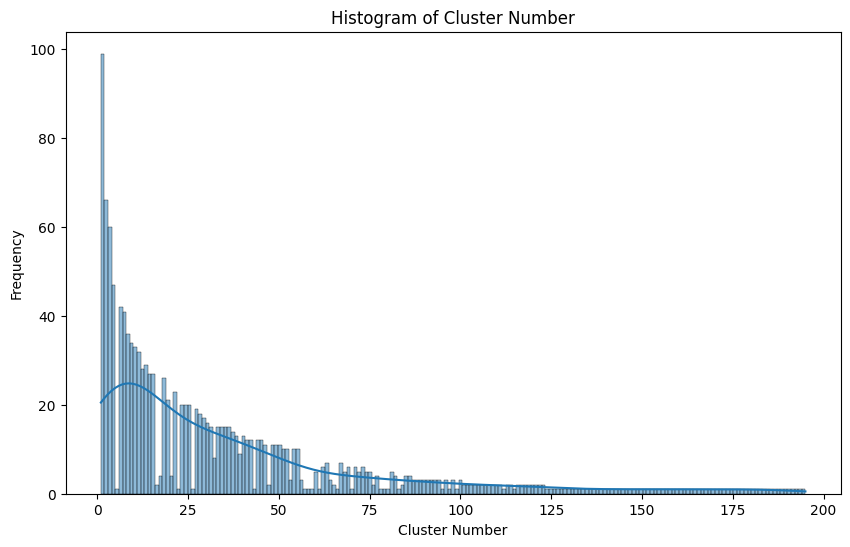

In [22]:
# Combine df_y and df_info
df_d = pd.concat([df_y, df_info], axis=1) # Pass the DataFrames as a list

df_d['cn_s'] = 'Cluster ' + df_d['Cluster_number'].astype(str)
# Create a mapping from Cluster_number values to numerical values
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(df_d['Cluster_number'].unique()))}
# Create the 'cn' column based on the mapping
df_d['cn'] = df_d['Cluster_number'].map(cluster_mapping)

fig = px.scatter(df_d, x="Cluster_number", y="Activity",# color="cn",
                 title="Activity vs. Cluster Number",
                 width=800, height=550)

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
fig.update_layout(hoverlabel_font_size=20)
app_marker = molplotly.add_molecules(fig=fig,df=df_d,
                                     smiles_col='SMILES', #title_col='Cmpd',
                                     #color_col='cn',
                                     caption_cols=['Cmpd'],
                                     fontsize=15, width=220)
# Assuming df_d is already created as in your provided code
plt.figure(figsize=(10, 6))  # Adjust figure size as needed
sns.histplot(df_d['Cluster_number'], kde=True, bins=195)  # kde=True adds a kernel density estimate
plt.title('Histogram of Cluster Number')
plt.xlabel('Cluster Number')
plt.ylabel('Frequency')

#fig.show()
app_marker.run(port=8660)
plt.show()

# SPLITING

In [23]:
# dividimos train test con stratified
discretizer = sklearn.preprocessing.KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="uniform")
splitter = StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, random_state=RANDOM_STATE)
# Reshape y_discrete to be a 2D array with one column
y_discrete = discretizer.fit_transform(df_y.values.reshape(-1, 1))
split, split_test = next(splitter.split(df_x.values, y_discrete))
fractions = ["train" if i in split else "test" for i in range(df_data.shape[0])]
df_data = df_data.assign(fraction=fractions)
df_d = df_d.assign(fraction=fractions)

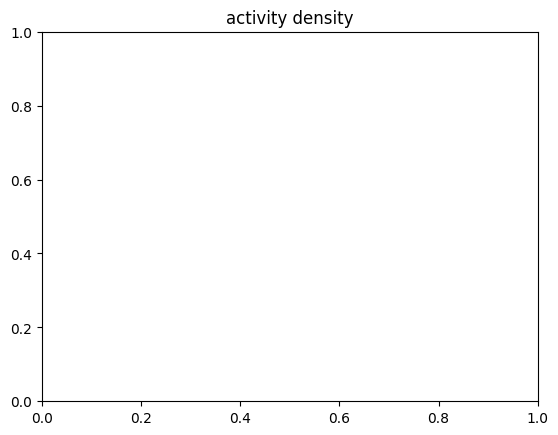

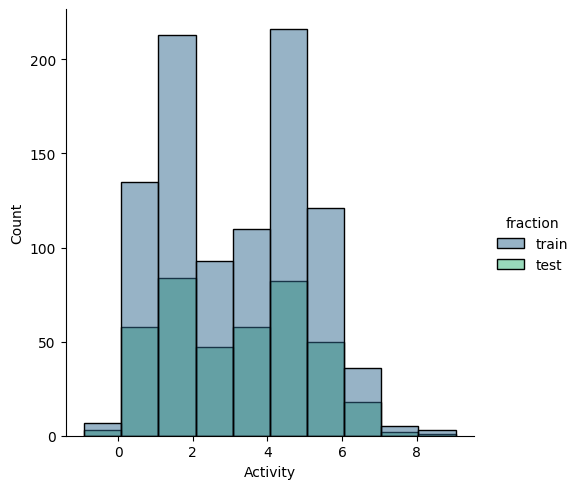

In [24]:
plt.title("activity density")
sns.displot(data=df_data, x="Activity", hue="fraction", alpha=0.5, bins=10, palette="viridis") # Cambia la paleta de colores s
plt.show()

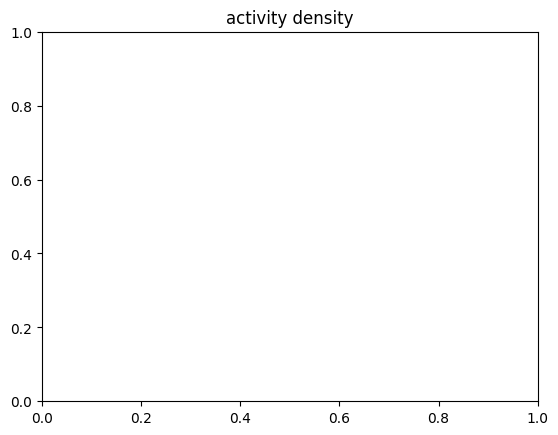

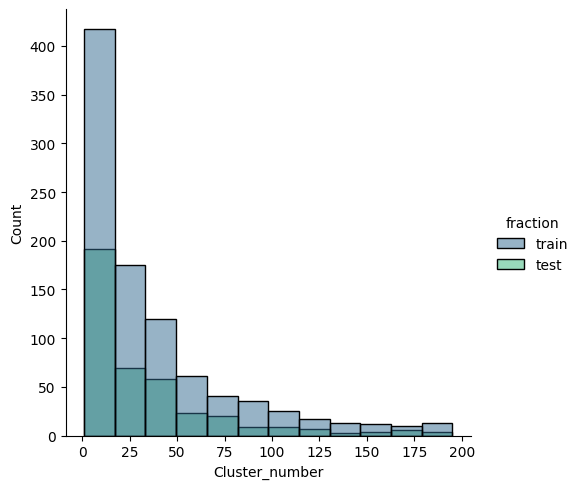

In [25]:
plt.title("activity density")
sns.displot(data=df_d, x="Cluster_number", hue="fraction", alpha=0.5, bins=12, palette="viridis") # Cambia la paleta de colores s
plt.show()

In [26]:
# sacamos los vectores (x, y) de interés
x_train = df_x[df_data["fraction"] == "train"].values
y_train = df_y[df_data["fraction"] == "train"].values
x_test = df_x[df_data["fraction"] == "test"].values
y_test = df_y[df_data["fraction"] == "test"].values
y_train = np.reshape(y_train, -1)
y_test = np.reshape(y_test, -1)

x_train = x_train.astype(float)
y_train = y_train.astype(float)
x_test = x_test.astype(float)
y_test = y_test.astype(float)

#x_train

# ENTRENAMIENTO

Se crea el modelo final final y se entrena

In [27]:
# @title
# creamos pipeline: el modelo final final
steps = [
    ("var0", VarianceThreshold(MIN_VARIANCE)),
    ("scaling", SCALER),
    ("feat_selector1", FEAT_SELECTOR1),
    ("feat_selector2", FEAT_SELECTOR2),
    ("regressor", REGRESSOR)
]
pipeline = Pipeline(steps, verbose=True)
pipeline = pipeline.fit(x_train, y_train)
pipeline.set_params(verbose=False)
pipeline

[Pipeline] .............. (step 1 of 5) Processing var0, total=   0.0s
[Pipeline] ........... (step 2 of 5) Processing scaling, total=   0.0s
[Pipeline] .... (step 3 of 5) Processing feat_selector1, total=  16.6s
[Pipeline] .... (step 4 of 5) Processing feat_selector2, total=   0.0s
[Pipeline] ......... (step 5 of 5) Processing regressor, total=   0.1s


Pipeline(steps=[('var0', VarianceThreshold(threshold=0)),
                ('scaling', StandardScaler()),
                ('feat_selector1',
                 SelectFromModel(estimator=RandomForestRegressor(min_samples_leaf=3,
                                                                 n_estimators=49,
                                                                 random_state=5712492),
                                 max_features=22)),
                ('feat_selector2', PCA(n_components=10, random_state=5712492)),
                ('regressor', SVR(C=25, epsilon=0.09))])

In [28]:
# @title
# analizamos paso a paso las transformaciones
z = x_train
for (i, step) in enumerate(pipeline[:-1]):
    print(f"Step {pipeline.steps[i][0]} ({i}): {step.__class__.__name__}")
    print(f"  Input: {z.shape}. Output: {step.transform(z).shape}")
    z = step.transform(z)

Step var0 (0): VarianceThreshold
  Input: (939, 1014). Output: (939, 886)
Step scaling (1): StandardScaler
  Input: (939, 886). Output: (939, 886)
Step feat_selector1 (2): SelectFromModel
  Input: (939, 886). Output: (939, 22)
Step feat_selector2 (3): PCA
  Input: (939, 22). Output: (939, 10)


# VALIDACIÓN

Se extraen los resultados y gráficas finales a reportar

In [29]:
from tqdm import tqdm

In [30]:
# @title
df = pd.DataFrame()
for metric in tqdm(METRICS, desc="Summary"):
    df_ = validate_summary(metric)
    df = pd.concat([df, df_]) # Use pd.concat to combine DataFrames
df

Summary: 100%|██████████| 2/2 [02:31<00:00, 75.67s/it]


,train,cv,test
r2,0.827157,0.547643,0.553751
neg_mean_squared_error,-0.568387,-1.475611,-1.418902


# DOMINIO DE APLICACIÓN

##Preparación de datos

In [31]:
# Primero entrena a los modelos de dominio de aplicación
transformer = pipeline[:-1] #Ccrea una nueva variable transformer. A esta variable se le asigna al útltimo paso del pipeline.

In [32]:
#Eentrenamiento de los modelos del Dominio de Aplicabilidad (AD). que estiman la fiabilidad de las predicciones
for model in APP_DOMAINS:
    z_train = transformer.transform(x_train)
    model = model.fit(z_train)
print("Numero de features después de las reducciones:", z_train.shape[0])
APP_DOMAINS

Numero de features después de las reducciones: 939


[LeverageMethod()]

In [33]:
# Guardemos los resultados del modelo de DA en un nuevo dataframe, para poder manipular los datos con mayor facilidad.
# Creamos un Dataframe vacío para guardar los resultados.
results_da = pd.DataFrame()

# Se ejecuta para modelo definido en APP_DOMAINS
for model in APP_DOMAINS:
    # Invoca a la función validate_domain para obtener del Dataframe de cada modelo
    df_model = validate_domain(model)
    # Agrega una columna para identificar el modelo
    df_model['Model'] = mname(model)

    # Concatenar el DataFrame de cada modela DA con el DataFrame de resultados_df
    results_da = pd.concat([results_da, df_model])

# Reset the index to the original index from df_data
results_da = results_da.set_index(df_data.index)
# Merge df_info with results_df based on their common index
results_da = pd.merge(df_info, results_da, left_index=True, right_index=True)

# Now results_df contains residuals and scores for all models and the original index.
# You can further process or analyze this DataFrame as needed.
#results_df

/tmp/ipykernel_992/157144716.py:13: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [34]:
for model in APP_DOMAINS:
    validate_domain(model)

/tmp/ipykernel_992/157144716.py:13: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [35]:
# En este nuevo dataframe agregaremos la información del cluster
#df_info = data[['Cmpd','SMILES']].copy() # Seleccionamos algunas columnas desde data
#df_info['Cluster_number'] = cluster_id

In [36]:
# Añadimos tres columna que nos permitirá visualizar la información de los clusters con plotly
results_da['fraction1'] = results_da['fraction'].astype('category').cat.codes
results_da['cn'] = results_da['Cluster_number'].astype('category').cat.codes
results_da['cn_s'] = 'Cluster ' + results_da['Cluster_number'].astype(str)
results_da = results_da.assign(Activity=df_data['Activity'])

In [37]:
# Create DA_data DataFrame
DA_data = results_da[['Cmpd', 'SMILES', 'Score','Cluster_number']].copy()
DA_data = DA_data.rename(columns={'Score': 'LeverageMethod_domain'})
#DA_data

## Apalancamiento

In [38]:
#________________Por si se enciman los datos_________________________________
a = results_da.copy()
#a = results_da[results_da['fraction1'].isin([0,1,2])]
#a = results_da[results_da['Cluster_number'].isin([2,1])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
# Crea una matriz de dispersión con Plotly

fig = px.scatter(a, x="Score", y="Residual",
                 #____color______________________
                 #color="Cluster_number",
                 #color="Activity",
                 color ='fraction',
                 #____color______________________
                 title="Residual vs. Leverage Score",
                 width = 900, height=500)

fig.add_vline(x=0, line_width=3, line_color="green")
fig.update_layout(    plot_bgcolor="white",  # Set plot background color
paper_bgcolor="white"   # Set paper background color
                          )
fig.add_hline(y=1, line_width=1, line_dash="dash", line_color="green")
fig.add_hline(y=0, line_width=1, line_color="black")
fig.add_hline(y=-0.57, line_width=1, line_dash="dash", line_color="green")


# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#fig.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig.update_layout(hoverlabel_font_size=20)
#fig.update_layout(showlegend=False) # This line removes the legend
#fig.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=5)) # Increase marker size

app_marker1 = molplotly.add_molecules(fig=fig,
                                      df=a,
                                      smiles_col='SMILES',
                                      # title_col='Cmpd',
                                      #_______color____________________________
                                      #color_col='Activity',
                                      #color_col='Cluster_number',
                                      color_col='fraction',
                                      #________________________________________
                                      fontsize=15, width=350,
                                      caption_cols=['Cluster_number','Activity'])
app_marker1.run(port=8061)
#fig.show()

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

In [39]:
# Guardamos la información del domino de aplicación en un dataframe llamado standardized_residuals_df
std_residuals = standardize_residuals(APP_DOMAINS[0])

# Fusiona df_info con standardized_residuals_df según su índice común.
std_residuals= std_residuals.set_index(df_data.index)
std_residuals = pd.merge(df_info, std_residuals, left_index=True, right_index=True)

#___________________________________________________________________________________________
### Gráfica "Standardized_Residual vs. Leverage Score"
#________________Por si se enciman los datos_________________________________
a = std_residuals.copy()
#a = std_residuals[std_residuals['fraction1'].isin([0,1,2])]
#a = std_residuals[std_residuals['Cluster_number'].isin([2,1])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________

fig = px.scatter(a, x="Score", y="Standardized_Residual", color="fraction",
                 #color="Cluster_number",
                 #facet_col="Model",
                 title="Standardized_Residual vs. Leverage Score",
                 width=900,height=500)
#____Formateo_____________________________________________________________________
# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#fig.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig.update_layout(hoverlabel_font_size=20)
#fig.update_layout(showlegend=False) # This line removes the legend
#fig.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=6)) # Increase marker size
#____respecto a linea_____________________________________________________________
fig.add_vline(x=0, line_width=3, line_color="green")
fig.add_hline(y=1, line_width=1, line_dash="dash", line_color="green")
fig.add_hline(y=0, line_width=1, line_color="black")
fig.add_hline(y=-1, line_width=1, line_dash="dash", line_color="green")
#_______________________________________________________________________________
app_marker2 = molplotly.add_molecules(fig=fig, df=a,
                                     smiles_col='SMILES',
                                    #  title_col='Cmpd',
                                     color_col='fraction',
                                      caption_cols=['Cmpd'],
                                     fontsize=10, width=210)

app_marker2.run(port=8062)
#fig.show()

/tmp/ipykernel_992/409828564.py:17: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

## Y Scramble

In [40]:
#validate_yscramble()

# Experimental vs Predicción

In [41]:
# @title
df_pve = df_info.assign(Experimental=df_y, Predicted=pipeline.predict(df_x))
# Assuming df_info and df_y have a common index
df_combin = pd.concat([df_pve, df_d['fraction']], axis=1)
# Ordena df_combin con Cluster_number de manera asecendente
df_combin = df_combin.sort_values(by='Cluster_number', ascending=True)
df_combin['cn_s'] = 'Cluster ' + df_combin['Cluster_number'].astype(str)
# Create a mapping from Cluster_number values to numerical values


#___Creamos con plotly una grafica de experimental vs predicted con df_combined_______________________________________
fig = px.scatter(df_combin, x="Experimental", y="Predicted",
                 #__color_______________________________________
                 color= 'fraction',
                 #color="Cluster_number",
                 #______________________________________________
                 title="Experimental vs Predicted",
                 #symbol="fraction",
                 width=900,height=650)

fig.add_shape(type="line", line=dict(dash='dash'),
              x0=df_combin["Experimental"].min(), y0=df_combin["Experimental"].min(),
              x1=df_combin["Experimental"].max(), y1=df_combin["Experimental"].max())

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=5)) # Increase marker size
fig.update_layout(hoverlabel_font_size=20)

app_marker = molplotly.add_molecules(fig=fig,
                                     df=df_combin,
                                     smiles_col='SMILES',
                                    # title_col='cn_s',
                                     color_col='fraction',
                                     #color_col='Cluster_number',
                                     caption_cols=['Cmpd', 'Cluster_number'],
                                     show_coords=False,
                                     fontsize=15, width=220)

app_marker.run(port=8060)
#fig.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning:

X has feature names, but VarianceThreshold was fitted without feature names

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

# EXPLORACIÓN

Evaluación final con las nuevas mols

## Definimos xplor

In [42]:
excel = True
SMILES_LIST = False
comercial = True

In [43]:
smiles_dict = {'Manu021':'CN1C[C@H]2N(CC(C3=CC=C(OC)C=C3)=O)C[C@@H]1C2',
               'Manu022':'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               #'Manu023' :'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@H](C4)C3)C=C21)=O',
               #'Manu024': 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               #'Manu024': 'O=C(C1=CC(F)=C(N2[C@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               #'Manu025' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OCC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               #'Manu026' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(F)C=CC=C6)=N3',
               #'Manu027' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=CC=C(F)C=C6)=N3',
               #'Manu028' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(C(F)(F)F)C=CC=C6)=N3',
               #'Manu029' : 'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(NC(C)=O)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               #'Manu030' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'ecp_01':'O=C1C2=C(C=C(F)C(N3CCN(C)CC3)=C2)C=NO1'}
comercial_drugs = {#______penicilinas________________________
               'penicilna G' : 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C',
               'oxaciline': 'CC1=C(C(=NO1)C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               'meticilina': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)C3=C(C=CC=C3OC)OC)C(=O)O)C',
               'amoxicilin': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)[C@@H](C3=CC=C(C=C3)O)N)C(=O)O)C',
               'minocyclin': 'CN(C)[C@H]1[C@@H]2C[C@@H]3CC4=C(C=CC(=C4C(=C3C(=O)[C@@]2(C(=C(C1=O)C(=O)N)O)O)O)O)N(C)C',
               'Ampicillin': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)[C@@H](C3=CC=CC=C3)N)C(=O)O)C',
               'penicilin V': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)COC3=CC=CC=C3)C(=O)O)C',
               'Dicloxacillin':'CC1=C(C(=NO1)C2=C(C=CC=C2Cl)Cl)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               'Piperacillin':'CCN1CCN(C(=O)C1=O)C(=O)N[C@H](C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               #_______b-lactamasa inhibitors____________________________________
               'clavulanic acid': 'C1[C@@H]2N(C1=O)[C@H](/C(=C/CO)/O2)C(=O)O',
               'tazobactam': 'C[C@@]1([C@@H](N2[C@H](S1(=O)=O)CC2=O)C(=O)O)CN3C=CN=N3',
               'sulbactam': 'CC1([C@@H](N2[C@H](S1(=O)=O)CC2=O)C(=O)O)C',

               #______cephalospprins_____________________
               'cephalexin': 'CC1=C(N2[C@@H]([C@@H](C2=O)NC(=O)[C@@H](C3=CC=CC=C3)N)SC1)C(=O)O',
               'ceftriaxone':'CN1C(=NC(=O)C(=O)N1)SCC2=C(N3[C@@H]([C@@H](C3=O)NC(=O)/C(=N\OC)/C4=CSC(=N4)N)SC2)C(=O)O',
               #_______inhibidores de pared___glucopeptidos____________________________
               'vancomicina': 'C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O',
               #____________lincosamidas
               'clindamicina': 'CCC[C@@H]1C[C@H](N(C1)C)C(=O)N[C@@H]([C@@H]2[C@@H]([C@@H]([C@H]([C@H](O2)SC)O)O)O)[C@H](C)Cl',
               #______tetraciclinas________________________
               'tetraciclina': 'C[C@@]1([C@H]2C[C@H]3[C@@H](C(=O)C(=C([C@]3(C(=O)C2=C(C4=C1C=CC=C4O)O)O)O)C(=O)N)N(C)C)O',
               #______sulfas_______________________
               'sulfamethoxazole':'CC1=CC(=NO1)NS(=O)(=O)C2=CC=C(C=C2)N',
               'sulfathiazole': 'C1=CC(=CC=C1N)S(=O)(=O)NC2=NC=CS2',
               #_______macrolides____________________________
               'azithromicyn': 'CC[C@@H]1[C@@]([C@@H]([C@H](N(C[C@@H](C[C@@]([C@@H]([C@H]([C@@H]([C@H](C(=O)O1)C)O[C@H]2C[C@@]([C@H]([C@@H](O2)C)O)(C)OC)C)O[C@H]3[C@@H]([C@H](C[C@H](O3)C)N(C)C)O)(C)O)C)C)C)O)(C)O',
               #inhibidor de la hidrofolato reductasa
               'trimethoprim': 'COC1=CC(=CC(=C1OC)OC)CC2=CN=C(N=C2N)N',
               #Fluoroquinolinas
               'levofloxacin': 'C[C@H]1COC2=C3N1C=C(C(=O)C3=CC(=C2N4CCN(CC4)C)F)C(=O)O',
               'ciprofloxacino' : 'C1CC1N2C=C(C(=O)C3=CC(=C(C=C32)N4CCNCC4)F)C(=O)O',
               'levofloxacin':'CN1C[C@@H]2C[C@H]1CN2C3=C(C=C4C(=C3)N(C=C(C4=O)C(=O)O)C5CC5)F'
               }


<>:30: SyntaxWarning:

invalid escape sequence '\O'

<>:30: SyntaxWarning:

invalid escape sequence '\O'

/tmp/ipykernel_992/4131901219.py:30: SyntaxWarning:

invalid escape sequence '\O'



In [44]:
xplor = pd.DataFrame()
if excel is True:
  #convierte smiles_dict en un dataframe
  #____DEBES DEFINIR OD Y NOMBRE DEL ARCHIVO
  !gdown --id 1GzL6IMPaiKvnsFjleu7jRvkOBuQNZOW5
  excel = pd.read_excel("XPLOR_PRoductos marinos.xlsx") #IMPORTANTE

  #____________________________________________
  # !gdown --id 1C4MQVLvAIYwBv1FJ-zzcJ6c91AuwdXyH #IMPORTANTE
  # excel = pd.read_excel("NPDIFACQUIM.xlsx") #IMPORTANTE
  # El archivo EXCEL SOLO DEBE TENER DOS columnas: 'SMILES' y 'Cmpd'
  #______________________________________________
  #! gdown --id 1IGs5emsGuqycnLA47j7YgwWbyb6SWnSL
  #xplor = pd.read_excel("kurt_xplor1_.xlsx")
  #_______________________________________________
  #! gdown --id 1Z5k3LY4lD8urfTUmGIl3HeEwX6hQaM6l
  #xplor = pd.read_excel("valid_smiles3.xlsx")
  #________________________________________________
  #! gdown --id 1_vE6EPXJYAiPR1g6kBl2uE5u_-aJ1oft
  #xplor = pd.read_excel("drugs.xlsx")
  #______________________________________
  #______________________________________________

  excel['G'] = 'xplor'
  excel['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, excel], ignore_index=True)
  print('Un archivo excel se adicionó a xplor')
else:
    print('NO se proceso EXCEL para adicionar a xplor')


if SMILES_LIST is True:
  #convierte smiles_dict en un dataframe
  sl = pd.DataFrame(list(smiles_dict.items()), columns=['Cmpd', 'SMILES'])
  sl['G'] = 'xplor'
  sl['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, sl], ignore_index=True)
  print('Un diccionario con SMILES se adicionó a xplor')
else:
  print('NO se procesó el DICCIONARIO para adicionar a xplor')

if comercial is True:
  #convierte comercial_drugs en un dataframe
  com_drugs = pd.DataFrame(list(comercial_drugs.items()), columns=['Cmpd', 'SMILES'])
  com_drugs['G'] = 'comercial'
  com_drugs['Cluster_number'] = len(set(cluster_id))+2
  xplor = pd.concat([xplor, com_drugs], ignore_index=True)
  print('Los fármacos comerciales se tomarán en cuenta')
else:
  print('NO se tomarán en cuenta los fármacos comerciales')

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1GzL6IMPaiKvnsFjleu7jRvkOBuQNZOW5
To: /content/XPLOR_PRoductos marinos.xlsx
100% 449k/449k [00:00<00:00, 7.37MB/s]
Un archivo excel se adicionó a xplor
NO se procesó el DICCIONARIO para adicionar a xplor
Los fármacos comerciales se tomarán en cuenta


## Descriptores, predicción y modelos DA

In [ ]:
mordred_descriptors = All_Mordred_descriptors(xplor['SMILES'])
xplor_mordred = pd.concat([xplor, mordred_descriptors], axis=1)

 15%|█▌        | 1525/10010 [03:16<21:03,  6.71it/s]  

/usr/local/lib/python3.13/dist-packages/mordred/_matrix_attributes.py:251: RuntimeWarning:

invalid value encountered in scalar power


 21%|██        | 2077/10010 [05:00<2:32:39,  1.15s/it]

/usr/local/lib/python3.13/dist-packages/mordred/_matrix_attributes.py:251: RuntimeWarning:

invalid value encountered in scalar power


 21%|██        | 2078/10010 [05:00<2:16:51,  1.04s/it]

...

 21%|██        | 2082/10010 [05:06<2:13:03,  1.01s/it]

/usr/local/lib/python3.13/dist-packages/mordred/_matrix_attributes.py:251: RuntimeWarning:

invalid value encountered in scalar power


 40%|███▉      | 3978/10010 [11:15<55:39,  1.81it/s]  

/usr/local/lib/python3.13/dist-packages/mordred/_matrix_attributes.py:251: RuntimeWarning:

invalid value encountered in scalar power
/usr/local/lib/python3.13/dist-packages/mordred/_matrix_attributes.py:251: RuntimeWarning:

invalid value encountered in scalar power


 48%|████▊     | 4837/10010 [14:31<40:38,  2.12it/s]

In [ ]:
# @title
# Seleccionar solo las características que estaban incluídas en el dataframe incial data
# Esta información adicional será guardada en una variable llamada df_val, con la que trabaja el pipeline
names = xplor_mordred["Cmpd"]
#df_x = xplor_mordred.drop(columns=["Cmpd", "SMILES", "G", "Cluster_number"])
df_val = xplor_mordred[df_x.columns] #Esta variable entra al pipeline
df_val = df_val.dropna()# Quita las filas que tienen NaN elementos
# Impute missing values using the mean
imputer = SimpleImputer(strategy='mean') # Or use other strategies like 'median', 'most_frequent'
df_val = pd.DataFrame(imputer.fit_transform(df_val), columns=df_val.columns, index=df_val.index)

In [ ]:
# @title
# Calculamos los valores de predicción y DA para el grupo de exploración, los guardamos en df
#es decir los valores de las nuevas moléculas a predecir o explorar.
df = pd.DataFrame({"pred": pipeline.predict(df_val.values)}, index=names) #pipeline.predict(df_val.values)} aplica toda la pipeline a df_val
for model in APP_DOMAINS:
    score = model.decision_function(pipeline[:-1].transform(df_val.values))
    df[f"{mname(model)}_domain"] = score
df

In [ ]:
# @title
# prompt: a df_v asignale indices
xplor_pred = df.reset_index()
xplor_pred = xplor_pred.drop(columns=['Cmpd'])
#xplor_pred['Cluster_number'] = xplor_mordred['Cluster_number']
# Concatenate xplor and df_v DataFrames
xplor_pred = pd.concat([xplor, xplor_pred], axis=1)

# PREDICCIONES

In [ ]:
#definimos el umbral
da_limit = 0
activity_limit = 5.5

In [ ]:
# Creamos uan gráfica de valores predichos respecto al Dominio de Aplicación
fig = px.scatter(xplor_pred, x="LeverageMethod_domain", y="pred",
                 title="LeverageMethod_domain vs pred",
                 width= 900,height = 500)

#___________Respecto a la linea_________________________________________________
fig.add_vline(x=0, line_width=3, line_color="green")
fig.add_hline(y=activity_limit, line_width=3, line_color="green")

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color)
#___________Respecto al formato_________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=xplor_pred,
                                     smiles_col='SMILES',
                                    #  title_col='Cmpd',
                                     #color_col='fraction',
                                     fontsize=15,
                                     width=220)
app_marker.run(port=8660)

In [ ]:

# Vamos a utiliza un umbral para filtrar los valores con leverage mayor que 0 y con valor predicted mayor a 5.2
filtered = xplor_pred[(xplor_pred['LeverageMethod_domain'] < da_limit) & (xplor_pred['pred'] >activity_limit)]
#____________________________________________________________________________
# Graficamos la información filtrada
fig = px.scatter(filtered, x="LeverageMethod_domain", y="pred",
                 title="LeverageMethod_domain vs pred",
                 width= 900,height = 500)
#___________Respecto a la linea_________________________________________________
fig.add_vline(x=0, line_width=3, line_color="green")
fig.add_hline(y=activity_limit, line_width=3, line_color="green")
fig.update_layout(plot_bgcolor="white",  # Set plot background color
    paper_bgcolor="white")   # Set paper background color
#_____________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                      df=filtered,
                                      smiles_col='SMILES',
                                      # title_col='Cmpd',
                                     caption_cols= ['Cmpd'],
                                      fontsize=15, width=220)

app_marker.run(port=8456)

In [ ]:
str(list(filtered['Cmpd']))

In [ ]:
save=True
if save is True:
  XPLOR = filtered[['Activity',	'Cmpd',	'SMILES',	'G']]
  XPLOR = filtered.rename(columns={'pred': 'Activity'})
  XPLOR.to_excel('XPLOR_marinep.xlsx', index=False)
  print('SE guardó XPLOR')
else:
  print('No se guardó XPLOR')

# ESPACIO QUÍMICO

### Espacio químico descriptores

In [ ]:
DATA_xplor = filtered.copy()
DATA_data = df_info.copy()
# prompt: combina DATA_data con df_y
DATA_data = pd.concat([DATA_data, df_y], axis=1)

In [ ]:
# Generar descriptores
DATA_data["HBA"] = [Descriptors.NumHAcceptors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["HBD"] = [Descriptors.NumHDonors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["RB"] = [Descriptors.NumRotatableBonds(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
# DATA_data["RB"] = [Descriptors.MinPartialCharge(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["LogP"] = [Descriptors.MolLogP(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["TPSA"] = [Descriptors.TPSA(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["MW"] = [Descriptors.MolWt(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]

In [ ]:
# Generar descriptores
DATA_xplor["HBA"] = [Descriptors.NumHAcceptors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["HBD"] = [Descriptors.NumHDonors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["RB"] = [Descriptors.NumRotatableBonds(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
# DATA_xplor["RB"] = [Descriptors.MinPartialCharge(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["LogP"] = [Descriptors.MolLogP(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["TPSA"] = [Descriptors.TPSA(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["MW"] = [Descriptors.MolWt(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]

In [ ]:
chemspace_data = DATA_data.copy()
#A chemspace_data agrega una columna llada G , que tenga el valor 'data' para todos los elementos
chemspace_data['G'] = 'data'
# Fusionar chemspace_data con DA_data según la columna 'Cmpd'
chemspace_data = pd.merge(chemspace_data, DA_data[['Cmpd', 'LeverageMethod_domain']], on='Cmpd', how='left')
# Now chemspace_data contains the 'LeverageMethod_domain' column from DA_data.
#chemspace_data

In [ ]:
# chemspace_xplor = DATA_xplor.copy()
# # prompt: en chemspace_xplor elimina las columnas: ZIN_ID, G, Component1, Component2, Component3
# chemspace_xplor = chemspace_xplor.drop(columns=['ZINC_ID', 'component1', 'component2', 'component3'], errors='ignore')
# # prompt: en chemspace_xplor cambia el nombre de la columna 'pred' por 'Activity'
# chemspace_xplor = chemspace_xplor.rename(columns={'pred': 'Activity'})
# # prompt: agrega la columna G a chemspace_xplor

#chemspace_xplor['G'] = 'comb'
#chemspace_xplor['Cluster_number'] = int(len(set(cluster_id))+1)

In [ ]:
chemspace_xplor = DATA_xplor.copy()
# Si 'Activity' ya existe y 'pred' también, elimina la 'Activity' original antes de renombrar 'pred'
if 'Activity' in chemspace_xplor.columns and 'pred' in chemspace_xplor.columns:
    chemspace_xplor = chemspace_xplor.drop(columns=['Activity'])
# en chemspace_xplor cambia el nombre de la columna 'pred' por 'Activity'
chemspace_xplor = chemspace_xplor.rename(columns={'pred': 'Activity'})

In [ ]:
chemspace_data.shape, chemspace_xplor.shape

In [ ]:
len(set(chemspace_data.columns)), len(set(chemspace_xplor.columns))

In [ ]:
# chemspace_xplor = chemspace_xplor.iloc[:, 1:]

In [ ]:
# Concatenate along rows (axis=0)
chemspace = pd.concat([chemspace_data, chemspace_xplor], axis=0, ignore_index=False)

# You may want to reset the index if needed:
# chemspace = chemspace.reset_index()

# A chemspace, agrega, una columna que se llame G2, que tenga valores numéricos para cada valor de G, esto servira mása adelante para visualizar datos en molplotly
# Create a mapping from 'G' values to numerical values
g_mapping = {'data': 1, 'xplor': 2, 'comb': 3}  # Example mapping
# Create the 'G2' column based on the mapping
chemspace['G2'] = chemspace['G'].map(g_mapping)
# Añadimos una columna que nos permitirá visualizar la información de los clusters con plotly

chemspace['cn_s'] = 'Cluster ' + chemspace['Cluster_number'].astype(str)
# Create a mapping from Cluster_number values to numerical values
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(chemspace['Cluster_number'].unique()))}
# Create the 'cn' column based on the mapping
chemspace['cn'] = chemspace['Cluster_number'].map(cluster_mapping)

### Representación de propiedades

In [ ]:
# @title
# prompt: has una matriz de dispersión con plotly, con el df chemspace

import plotly.express as px
#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#________________Definimos la gráfica______________________________
fig1 = px.scatter_matrix(data_frame=a,
                         #data_frame=a, #Por si se enciman los datos
                         #_________________________________
                         dimensions=["HBA", "HBD", "RB", "LogP", "TPSA", "MW", 'Activity'
                                     ],
                         #_______color_________________________________________
                         color="G",
                         #color="cn",
                         #_________________________________
                         #color_discrete_sequence=px.colors.qualitative.Dark24,
                         #____________Color___________________________________
                         title='Matriz de dispersión del Espacio Químico, Descriptores Individuales ',
                         width=1300,
                         height=1600 )
#________________Formato________________________________________________________
fig1.update_layout(plot_bgcolor="white", #paper_bgcolor="gray"
                   )  # Set plot background color
fig1.update_traces(diagonal_visible=False,
                  #  marker=dict(line=dict(width=1, color='black'))
                   ) #Added marker settings
fig1.update_traces(marker=dict(size=3)) # Increase marker size
#_______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig1,
                                     #_________________________________________
                                     df=a,
                                     #df=a,
                                     #_________________________________________
                                     smiles_col='SMILES',
                                     #title_col='Cmpd',
                                     #____color_______________________________
                                     color_col='G',
                                     #color_col='cn',
                                     #________________________________________
                                     caption_cols=['Cmpd'],
                                     show_coords=True,
                                     fontsize=20, width=350)
app_marker.run(port=8066)
#fig.show()

In [ ]:
# prompt: repite la matriz de dispersión con plt

fig1 = plt.figure(figsize=(10, 8))  # Adjust figure size as needed
sns.pairplot(data=a,
             vars=['MW',"HBA", "HBD", "RB",
                   "LogP",
                     "TPSA",
                    "MW",
                   'Activity'],
             hue="G", # Use the original string column for hue
             palette="Paired_r", # You can change the color palette
             diag_kind="kde", # Use kernel density estimate for diagonal plots
            #  plot_kws={'s': 10, 'edgecolor': 'black', 'linewidth': 1}
             ) # Adjust marker size and outline

plt.suptitle('Matriz de dispersión del Espacio Químico, Descriptores Individuales', y=1.02) # Add a title to the overall plot
plt.show()


In [ ]:
# Creamos una gráfica donde se puden ver las propiedades individuales de las moléculas a evaluar comparadas con
# lás moléculas de los datos iniciales

#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#________________Definimos la gráfica______________________________

fig = px.scatter(data_frame=a, x="MW",# y="Activity",
                 y='Activity',
                 title="Características individuales",
                 #_______Color_________________________
                 color = 'G',
                 #color = 'cn'
                 )
#________________Formato________________________________________________________
fig.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Set background color
fig.update_traces(marker=dict(size=3)) # Increase marker size
# fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
##_________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=a,
                                     smiles_col='SMILES',
                                     #title_col='cn_s',
                                     #color_col = 'cn',
                                     color_col='G',
                                     fontsize=20, width=350)
app_marker.run(port=8067)
#fig.show()

In [ ]:
# Creamos una gráfica de dispersión en 3D donde se puden ver las propiedades individuales de las moléculas a evaluar comparadas con
# lás moléculas de los datos iniciales

#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#___________________________________________________________________________
#________________Definimos la gráfica______________________________
fig = px.scatter_3d(data_frame=a, x="MW", y="LogP", z="Activity",
                    title="Características individuales",
                    #_____color________
                    color='G',
                    #color = 'cn',
                    height= 900, width=900,
                    )
#________________Formato________________________________________________________
fig.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Set background color

fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=3)) # Increase marker size
#_______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=a,
                                     smiles_col='SMILES',
                                     #title_col='cn_s',
                                     color_col='G',
                                     fontsize=15,
                                     width=210)
app_marker.run(port=8068)

# Representación del Espacio Químico por PCA

### Preparación

In [ ]:
data_k=chemspace.copy()
#Dividir matriz
data_k = data_k.iloc[:,4:10].values # Seleccionar columnas con descriptores
data_k = pd.DataFrame(data_k)
#data

In [ ]:
# Normalizar datos
from sklearn.preprocessing import StandardScaler
data_std = StandardScaler().fit_transform(data_k)

In [ ]:
# pca.fit
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca_results = pca.fit_transform(data_std)
#pca_results

In [ ]:
# Seleccionar impormación complementaria
label = chemspace[["Cmpd", "SMILES", "Activity", 'G', 'Cluster_number']]
label = label.to_numpy()

In [ ]:
# Concatenar arrays de numpy
arr = np.concatenate((label, pca_results), axis = 1)
# Crear un nuevo dataframe
pca_dataset = pd.DataFrame(data=arr, columns = ['Cmpd',"SMILES", "Activity",'G','Cluster_number','component1', 'component2', 'component3'])
#pca_dataset.head(2)

In [ ]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(pca.n_components):
  loadings.append(pca.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=data_k.columns)
# Renombramos las columnas
pca_loadings = pca_loadings.rename(columns={0: "HBA", 1: "HBD", 2: "RB", 3: "LogP", 4: "TPSA", 5: "MW"})
# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)

In [ ]:
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)

###  PCA representación de pesos

In [ ]:
# @title
# Crea una figura
figx = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figx.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figx.update_layout(title="Contribución de los Descriptores a cada PC para el Espacio Químico",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
figx.show()# Muestra la figura

### PCA varianza acumulada

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(data_k)
X_train_std = sc.transform(data_k)

pca = PCA()

# Determine transformed features
X_train_pca = pca.fit_transform(X_train_std)

# Determine explained variance using explained_variance_ration_ attribute
exp_var_pca = pca.explained_variance_ratio_
#
# Cumulative sum of eigenvalues; This will be used to create step plot
# for visualizing the variance explained by each principal component.
cum_sum_eigenvalues = np.cumsum(exp_var_pca)
#
# Create the visualization plot
import matplotlib.pyplot as plt
plt.bar(range(0,len(exp_var_pca)), exp_var_pca, alpha=0.5, align='center', label='Individual explained variance')
plt.step(range(0,len(cum_sum_eigenvalues)), cum_sum_eigenvalues, where='mid',label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [ ]:
# # Add the 'Levarage_domain' column to pca_dataset
# da = chemspace['LeverageMethod_domain']  # Using chemspace DataFrame to access the column
# # Reset the index of pca_dataset to match chemspace
# pca_dataset = pca_dataset.reset_index(drop=True)
# # Add the new column to pca_dataset
# pca_dataset['LeverageMethod_domain'] = da

In [ ]:
da = chemspace['LeverageMethod_domain']  # Using chemspace DataFrame to access the column
da = da.reset_index(drop=True) # Reset the index of da itself
pca_dataset = pca_dataset.reset_index(drop=True)
pca_dataset['LeverageMethod_domain'] = da

## Representación del espacio químico por PCA


###2D

In [ ]:
# Crea una columna en pca_dataset que se llamará cn, tendra valores numéricos uno para cada tipo de valor de Cluster_number
# Create a mapping from Cluster_number values to numerical values
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(pca_dataset['Cluster_number'].unique()))}
# Create the 'cn' column based on the mapping
pca_dataset['cn'] = pca_dataset['Cluster_number'].map(cluster_mapping)
# Crea una columna en pca_datset, se llamará cn_s, tendra valores en cadenas dirán cluster + n, donde es el número de cluster
pca_dataset['cn_s'] = 'cluster ' + pca_dataset['cn'].astype(str)
# Create the 'G2' column based on the mapping
pca_dataset['fraction1'] = pca_dataset['G'].map(g_mapping)

In [ ]:
#Graficar gráfica de dispersión Activity vs PC1

#________________Por si se enciman los datos_________________________________
a = pca_dataset.copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]
# a = pca_dataset[pca_dataset['cn'].isin([1,2,3,4,5,6,.7,8,9,10,11,12,13])]
#________________Definimos la gráfica_______________________________________

dato1='component1'
dato3='Activity'
#________________
dato2='component2'
#___________________________________________________________________________
fig_pca = px.scatter(data_frame=a, #Por si se enciman los datos
                     #____coordenadas______________--
                     x=dato1,y=dato2,
                     #_____Color_____________
                    #  color='cn',
                     color='G',
                     #color_discrete_sequence='viridis',
                     #______________________
                     title=f'{dato2} vs {dato1}',
                     width=800,height=600)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
# fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=6)) # Increase marker size


# Añadir anotaciones SÓLO para puntos 'comerciales'
for index, row in a.iterrows():
    if row['G'] == 'comercial': # Solo agregue etiquetas para el grupo 'comercial'
        fig_pca.add_annotation(
            x=row['component1'],
            y=row['component2'],
            text=row['Cmpd'],
            showarrow=False,
            yshift=10,  # Desplazar el texto ligeramente por encima del punto
            # xshift=40,  # Desplazar el texto ligeramente a la derecha del punto
            font=dict(size=10, color="black"))


#______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig_pca,
                                     #_____________dataframe___________________
                                     df=a,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________
                                     color_col='G',
                                    #  color_col='cn',
                                     #_________________________________________
                                    fontsize=20, width=350,
                                     caption_cols=[dato3],
                                     show_coords=False)
app_marker.run(port=8069)
#fig_pca.show()
figx.update_layout(width=800, height=250)
figx.show()

### 3D

Activity vs PC1 Vs PC2

In [ ]:
#Grafica de dispersión en 3D Activity vs PC1 vs PC2
#________________Por si se enciman los datos_________________________________

a = pca_dataset.copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]
#a = pca_dataset[pca_dataset['cn'].isin([6,9,#10,11,12,13])]

#________________Definimos la gráfica_______________________________________
dato1='component1'
#dato2='Activity'
dato2='component3'
dato3='component2'
#_________
dato4='Activity'
#dato4='component3'
#__________________________________________________________________________
fig_pca = px.scatter_3d(data_frame=a,
                        #data_frame=a, #Por si se enciman los datos
                        #______coordenadas__________________________________
                        x=dato3,
                        y=dato1,
                        z=dato2,
                        #______color________________________________________
                        #color='G',
                        color='cn',
                        #___________________________________________________
                        title=f'{dato2} vs {dato1} vs {dato3}',
                        width=900, height=900)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=12)) # Increase marker size
#______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig_pca,
                                     #___________dataframe__________________
                                     df=a,
                                     #df=a,
                                     #______________________________________
                                     smiles_col='SMILES',
                                     title_col='cn_s',
                                     #____________color_____________________
                                     color_col='cn',
                                     #color_col='G',
                                     #________________________________________
                                     show_coords=False,
                                     caption_cols=[dato4,'Cmpd'],
                                     fontsize=15, width=210)
app_marker.run(port=8060)
figx.show()

# Representación del Espacio Químico por T-SNE

In [ ]:
# @title
## Entrenar modelo t-SNE
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
data_tsne = chemspace.copy()
data_tsne = data_tsne.drop(labels = ["Cmpd", "Cluster_number","SMILES",'Activity','G', 'LeverageMethod_domain',	'G2',	'cn_s',	'cn'],axis = 1)
data_tsne = StandardScaler().fit_transform(data_tsne)
tsne = TSNE(n_components=3, verbose=1, perplexity=5, max_iter=10000, early_exaggeration=1)
tsne_results = tsne.fit_transform(data_tsne)
#tsne_results
# Seleccionar impormación complementaria
label = chemspace[["Cmpd", "Cluster_number","SMILES",'Activity','G', 'LeverageMethod_domain',	'G2',	'cn_s',	'cn']]
label = label.to_numpy()

# Concatenar arrays de numpy
arr = np.concatenate((label, tsne_results), axis = 1)

# Crear un nuevo dataframe
tsne_dataset = pd.DataFrame(data=arr,
                            columns = ["Cmpd", "Cluster_number","SMILES",'Activity','G','LeverageMethod_domain','G2', 'cn_s',	'cn','axis1', 'axis2','axis3'])
#tsne_dataset

# prompt: ordena tsne_dataset por orden ascendente en cn_s

tsne_dataset = tsne_dataset.sort_values(by=['cn_s'])
#tsne_dataset

# prompt: en tsne_dataset elimina los lementos repetidos

# Eliminar filas duplicadas en tsne_dataset basándose en la columna 'SMILES'
tsne_dataset = tsne_dataset.drop_duplicates(subset='SMILES')
#tsne_dataset


# Graficar

#_______________________________________________________________________________________________________
import plotly.express as px
import molplotly

fig_tsne2d = px.scatter(tsne_dataset,
                      x='axis1', y='axis2',
                      color='cn',
                      title='t-SNE',
                      #color_discrete_sequece=px.colors.qualitative.Plotly,
                      width=900,height=700)

# Set background color to white
fig_tsne2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne2d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne2d.update_traces(marker=dict(size=12)) # Increase marker size
# También puedes usar una sintaxis más directa (atajo):
fig_tsne2d.update_layout(hoverlabel_font_size=20)

#fig_tsne.update_layout(showlegend=False) # This line removes the legend
#fig_tsne.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="center", x=-10.0))
#app_marker2d = molplotly.add_molecules(fig=fig_tsne2d,
#                                       df=tsne_dataset,
#                                       smiles_col='SMILES',
#                                       title_col='Cmpd',
#                                       color_col='cn',
#                                       width=350, fontsize= 25,
#                                       caption_cols=['cn_s','Activity'],
#                                       show_coords=False
#                                       )
#_________________________________________________________________________________________________________


fig_tsne3d = px.scatter_3d(tsne_dataset,
                      x='axis1', y='axis3', z='axis2',
                      color='Cluster_number',
                      title='t-SNE',
                      hover_data={'cn_s':True,'Activity':True, 'axis1': False, 'axis2': False, 'axis3':False},
                      hover_name='Cmpd',
                      width=900,height=700)

# Set background color to white
fig_tsne3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne3d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne3d.update_traces(marker=dict(size=12)) # Increase marker size
# También puedes usar una sintaxis más directa (atajo):
fig_tsne3d.update_layout(hoverlabel_font_size=20)


#fig_tsne.update_layout(showlegend=False) # This line removes the legend
#fig_tsne.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="center", x=-10.0))
#                                       )
#_____________________________________________________________________________________________________
# app_marker2d.run(port=8060)
fig_tsne2d.show()
fig_tsne3d.show()

In [ ]:
# @title
## Entrenar modelo t-SNE
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import plotly.express as px
import molplotly

data_tsne = chemspace.copy()
data_tsne = data_tsne.drop(labels = ["Cmpd", "Cluster_number","SMILES",'Activity','G', 'LeverageMethod_domain',	'G2',	'cn_s',	'cn'],axis = 1)
data_tsne = StandardScaler().fit_transform(data_tsne)
tsne = TSNE(n_components=3, verbose=1, perplexity=5, max_iter=10000, early_exaggeration=1)
tsne_results = tsne.fit_transform(data_tsne)
#tsne_results
# Seleccionar impormación complementaria
label = chemspace[["Cmpd", "Cluster_number","SMILES",'Activity','G', 'LeverageMethod_domain',	'G2',	'cn_s',	'cn']]
label = label.to_numpy()

# Concatenar arrays de numpy
arr = np.concatenate((label, tsne_results), axis = 1)

# Crear un nuevo dataframe
tsne_dataset = pd.DataFrame(data=arr,
                            columns = ["Cmpd", "Cluster_number","SMILES",'Activity','G','LeverageMethod_domain','G2', 'cn_s',	'cn','axis1', 'axis2','axis3'])
#tsne_dataset

# prompt: ordena tsne_dataset por orden ascendente en cn_s

tsne_dataset = tsne_dataset.sort_values(by=['cn_s'])
#tsne_dataset

# prompt: en tsne_dataset elimina los lementos repetidos

# Eliminar filas duplicadas en tsne_dataset basándose en la columna 'SMILES'
tsne_dataset = tsne_dataset.drop_duplicates(subset='SMILES')
#tsne_dataset


# Graficar

#_______________________________________________________________________________________________________


fig_tsne2d = px.scatter(tsne_dataset,
                      x='axis1', y='axis2',
                      color='cn',
                      title='t-SNE',
                      # Add hover_data to control what appears on hover and in trace names
                      hover_data={'cn_s':True, 'Activity':True, 'axis1': False, 'axis2': False},
                      hover_name='Cmpd',
                      #color_discrete_sequece=px.colors.qualitative.Plotly,
                      width=900,height=700)

# Set background color to white
fig_tsne2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne2d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne2d.update_traces(marker=dict(size=12)) # Increase marker size
# También puedes usar una sintaxis más directa (atajo):
fig_tsne2d.update_layout(hoverlabel_font_size=20)

#fig_tsne.update_layout(showlegend=False) # This line removes the legend
#fig_tsne.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="center", x=-10.0))
app_marker2d = molplotly.add_molecules(fig=fig_tsne2d,
                                      df=tsne_dataset,
                                      smiles_col='SMILES',
                                      # title_col='Cmpd',
                                     color_col='cn',
                                      width=350, fontsize= 25,
                                      caption_cols=['cn_s','Activity'],
                                      show_coords=False
                                      )
#_________________________________________________________________________________________________________


fig_tsne3d = px.scatter_3d(tsne_dataset,
                      x='axis1', y='axis3', z='axis2',
                      color='Cluster_number',
                      title='t-SNE',
                      hover_data={'cn_s':True,'Activity':True, 'axis1': False, 'axis2': False, 'axis3':False},
                      hover_name='Cmpd',
                      width=900,height=700)

# Set background color to white
fig_tsne3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne3d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne3d.update_traces(marker=dict(size=12)) # Increase marker size
# También puedes usar una sintaxis más directa (atajo):
fig_tsne3d.update_layout(hoverlabel_font_size=20)


#fig_tsne.update_layout(showlegend=False) # This line removes the legend
#fig_tsne.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="center", x=-10.0))
#                                       )
#_____________________________________________________________________________________________________
app_marker2d.run(port=8060)
# fig_tsne2d.show()
fig_tsne3d.show()

#UMAP

In [ ]:
# ! pip install umap-learn

In [ ]:
import umap

In [ ]:
# Select the descriptor columns from chemspace for UMAP
descriptor_cols = ['HBA', 'HBD', 'RB', 'LogP', 'TPSA', 'MW']
X_descriptors = chemspace[descriptor_cols].copy()

# Handle potential NaN values by imputing with the mean (similar to previous steps for other models)
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_descriptors)

# Apply StandardScaler to the descriptors
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Apply UMAP dimensionality reduction (using 3 components for more detail, can be changed to 2)
reducer = umap.UMAP(n_components=3,
                   # n_neighbors = 15,
                    random_state=RANDOM_STATE)
umap_results = reducer.fit_transform(X_scaled)

# Create a DataFrame for UMAP results
umap_df = pd.DataFrame(umap_results,
                       columns=['UMAP1', 'UMAP2', 'UMAP3'])

# Add relevant original columns to the UMAP DataFrame
umap_df['Cmpd'] = chemspace['Cmpd'].values
umap_df['SMILES'] = chemspace['SMILES'].values
umap_df['Activity'] = chemspace['Activity'].values
umap_df['Cluster_number'] = chemspace['Cluster_number'].values
umap_df['G'] = chemspace['G'].values



In [ ]:
import plotly.express as px
import warnings

warnings.filterwarnings("ignore", message="JupyterDash is deprecated, use Dash instead.")

# Prepare data for plotting, ensuring 'G' is properly handled for color
umap_df['G_category'] = umap_df['G'].astype('category')

# 2D UMAP Scatter Plot
fig_umap2d = px.scatter(umap_df,
                        x='UMAP1', y='UMAP2',
                        color='G_category',
                        color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'orange'},
                        title='2D UMAP Visualization of Chemical Space',
                        width=900, height=700)

fig_umap2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_umap2d.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_umap2d.update_traces(marker=dict(size=12))
fig_umap2d.update_layout(hoverlabel_font_size=20)


# # Añadir anotaciones SÓLO para puntos 'comerciales'
# for index, row in umap_df.iterrows():
#     if row['G'] == 'comercial': # Solo agregue etiquetas para el grupo 'comercial'
#         fig_umap2d.add_annotation(
#             x=row['UMAP1'],
#             y=row['UMAP2'],
#             text=row['Cmpd'],
#             showarrow=False,
#             yshift=10,  # Desplazar el texto ligeramente por encima del punto
#             # xshift=40,  # Desplazar el texto ligeramente a la derecha del punto
#             font=dict(size=10, color="black"))





app_umap2d = molplotly.add_molecules(
    fig=fig_umap2d,
    df=umap_df,
    smiles_col='SMILES',
    color_col='G_category',
    caption_cols=['Cmpd', 'Activity', 'Cluster_number', 'G'],
    fontsize=15, width=220
)




print('2D UMAP plot created. Running on port 8717.')
app_umap2d.run(port=8717)

# 3D UMAP Scatter Plot
fig_umap3d = px.scatter_3d(umap_df,
                         x='UMAP1', y='UMAP2', z='UMAP3',
                         color='G_category',
                         color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'orange'},
                         title='3D UMAP Visualization of Chemical Space',
                         width=900, height=900)

fig_umap3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_umap3d.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_umap3d.update_traces(marker=dict(size=8))
fig_umap3d.update_layout(hoverlabel_font_size=20)

app_umap3d = molplotly.add_molecules(
    fig=fig_umap3d,
    df=umap_df,
    smiles_col='SMILES',
    color_col='G_category',
    caption_cols=['Cmpd', 'Activity', 'Cluster_number', 'G'],
    fontsize=15, width=210
)

print('3D UMAP plot created. Running on port 8718.')
app_umap3d.run(port=8718)

# REPRESENTACIÓN DEL SOPORTE VECTORIAL

## Preparación de Dataframes

In [ ]:
df_info = df_info.assign(fraction=fractions)

In [ ]:
# Create column names
column_names = [f'PC{i}' for i in range(1, n_pca + 1)]

In [ ]:
# Añadimos tres columna que nos permitirá visualizar la información de los clusters con plotly
df_info['fraction1'] = df_info['fraction'].astype('category').cat.codes
df_info['cn'] = df_info['Cluster_number'].astype('category').cat.codes
df_info['cn_s'] = 'Cluster ' + df_info['Cluster_number'].astype(str)
print(df_info.shape)
#df_info.head()

### test

In [ ]:
# Apply the pipeline up to the specified step
df_pca_test_data = pipeline[:-1].transform(x_test)

In [ ]:
# Create the DataFrame using the transformed data
df_pca_test= pd.DataFrame(data=df_pca_test_data[:,:n_pca], columns=column_names)
df_info_train = df_info[df_info['fraction'] == 'train']
df_info_test = df_info[df_info['fraction'] == 'test']
df_pca_test = df_pca_test.assign(Activity = y_test)
df_info_test = df_info_test.reset_index(drop=True)
df_pca_test = df_pca_test.reset_index(drop=True)
df_pca_test = pd.concat([df_pca_test, df_info_test], axis=1)
#df_pca_test

### val

In [ ]:
# Apply the pipeline up to the specified step
df_pca_val_data = pipeline[:-1].transform(df_val)

In [ ]:
# Create the DataFrame using the transformed data
df_pca_val = pd.DataFrame(data=df_pca_val_data[:,:n_pca], columns=column_names)
df_pca_val = df_pca_val.assign(Activity = xplor_pred['pred'])
df_pca_val = pd.concat([df_pca_val, xplor], axis =1)
df_pca_val['Cluster_number'] = 13
df_pca_val['fraction'] = 'xplor'
df_pca_val = df_pca_val.assign(da =xplor_pred['LeverageMethod_domain'])
#df_pca_val

filtered = df_pca_val[(df_pca_val['da'] > da_limit) & (df_pca_val['Activity'] >activity_limit)]
filtered = filtered.drop('da', axis =1)
filtered = filtered.reset_index(drop=True)
#filtered
# Añadimos tres columna que nos permitirá visualizar la información de los clusters con plotly
filtered['fraction1'] = 2
filtered['cn'] = len(set(cluster_id)) + 1
filtered['cn_s'] = 'Cluster ' + filtered['Cluster_number'].astype(str)

### train

In [ ]:
# Apply the pipeline up to the specified step
df_pca_train_data = pipeline[:-1].transform(x_train)

In [ ]:
# Create the DataFrame using the transformed data
df_pca_train = pd.DataFrame(data=df_pca_train_data[:,:n_pca], columns=column_names)

#df_pca_train.shape
df_pca_train = df_pca_train.assign(Activity = y_train)
#df_pca_train
df_info_train = df_info_train.reset_index(drop=True)
df_pca_train = df_pca_train.reset_index(drop=True)
df_pca_train = pd.concat([df_pca_train, df_info_train], axis=1,)
#df_pca_train

###concatenated_df

In [ ]:
# Concatenate ja, df_pca_test, and df_pca_val
concatenated_df = pd.concat([df_pca_train, df_pca_test, filtered], axis=0, #ignore_index=True
                            )
# prompt: ordena concatenated_df  con cn_s de amnera ascendenete
concatenated_df = concatenated_df.sort_values(by=['cn_s'], ascending=True)

## Análisis de PCA

In [ ]:
# @title
# prompt: # prompt: haz una gráfica que expli que la varianza acumulda y varianza individual de cada PC, con plot ly, con un ofndo blanco, pon marcas en el eje de las absisas a la altura de 0.8, 0.9, 0.95, 0.99

import plotly.graph_objects as go

# Calcula la varianza explicada acumulada

cumulative_variance = np.cumsum(FEAT_SELECTOR2.explained_variance_ratio_)
# Crea la figura
fig = go.Figure()

# Agrega la traza de varianza individual
fig.add_trace(go.Bar(
    x=[f'PC{i+1}' for i in range(FEAT_SELECTOR2.n_components_)],
    y=FEAT_SELECTOR2.explained_variance_ratio_,
    name='Varianza Individual'
))

# Agrega la traza de varianza acumulada
fig.add_trace(go.Scatter(
    x=[f'PC{i+1}' for i in range(FEAT_SELECTOR2.n_components_)],
    y=cumulative_variance,
    mode='lines+markers',
    name='Varianza Acumulada',
    line=dict(color='green')
))

# Configura el diseño
fig.update_layout(
    title='Varianza Explicada por Componentes Principales para Regresión',
    xaxis_title='Componente Principal',
    yaxis_title='Varianza Explicada',
    plot_bgcolor='white',
    xaxis=dict(
        showgrid=True,
        tickmode='linear',
        dtick=1
    ),
    yaxis=dict(
        showgrid=True
    ),
    shapes=[
        dict(
            type='line',
            yref='y', y0=0.8, y1=0.8,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        ),
        dict(
            type='line',
            yref='y', y0=0.9, y1=0.9,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        ),
        dict(
            type='line',
            yref='y', y0=0.95, y1=0.95,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        ),
        dict(
            type='line',
            yref='y', y0=0.99, y1=0.99,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        )
    ]
)

# Muestra la gráfica
fig.show()


In [ ]:
df_pca_train_ = df_pca_train.select_dtypes('number').copy()

In [ ]:
# @title
# prompt: # prompt: coloca juntas en una misma celda las dos ultimas gráficas de linea continua, uqe se comparen con el eje de las absisas, correlación en color verde y correlación en color azul

# Calcula las covarianzas con respecto a 'activity'
#covarianzas_activity = cov_matrix['activity'].drop('activity')

# Calcula los coeficientes de correlación
covarianzas_activity = df_pca_train_.cov()['Activity'].drop('Activity')

# Crea un DataFrame para la gráfica de covarianzas
df_covarianzas = pd.DataFrame({
    'Componente Principal': covarianzas_activity.index,
    'Covarianza': covarianzas_activity.values
})

# Calcula los coeficientes de correlación
correlations = df_pca_train_.corr()['Activity'].drop('Activity')

# Crea un DataFrame para la gráfica de correlaciones
df_correlations = pd.DataFrame({
    'Componente Principal': correlations.index,
    'Correlación': correlations.values
})

# Crea la figura de Plotly con ambas gráficas
fig = go.Figure()

# Agrega la línea de covarianzas
fig.add_trace(go.Scatter(
    x=df_covarianzas['Componente Principal'],
    y=df_covarianzas['Covarianza'],
    mode='lines+markers',
    name='Covarianza',
    line=dict(color='green')
))

# Agrega la línea de correlaciones
fig.add_trace(go.Scatter(
    x=df_correlations['Componente Principal'],
    y=df_correlations['Correlación'],
    mode='lines+markers',
    name='Correlación',
    line=dict(color='blue')
))

# Agrega una línea de referencia en el eje 0
fig.add_shape(
    type='line',
    x0=df_covarianzas['Componente Principal'].iloc[0],
    x1=df_covarianzas['Componente Principal'].iloc[-1],
    y0=0,
    y1=0,
    line=dict(color='black', dash='dash')
)

# Configura el título y etiquetas de los ejes
fig.update_layout(
    title='Covarianzas y Correlaciones de los Componentes Principales para egresión con respecto a la Actividad',
    xaxis_title='Componente Principal',
    yaxis_title='Valor',
    plot_bgcolor='white',
    paper_bgcolor='white',
    legend=dict(x=0.8, y=0.1)
)

# Muestra la gráfica
fig.show()


In [ ]:
# creamos pipeline: el modelo final final
steps3 = [
    ("var0", VarianceThreshold(MIN_VARIANCE)),
    ("scaling", SCALER),
    ("feat_selector1", FEAT_SELECTOR1),
    #("feat_selector2", FEAT_SELECTOR2),
    #("regressor", REGRESSOR)
]
pipeline3 = Pipeline(steps3, verbose=True)
pipeline3 = pipeline3.fit(x_train, y_train)
pipeline3.set_params(verbose=False)
#pipeline

In [ ]:
# prompt: haz un data frame con las caracteristicas seleccionadas por el pipeline, las columnas serán nombradas con el nombre de las carcteristicas seleccionadas


selected_feature_indices = pipeline3.named_steps['feat_selector1'].get_support(indices=True)
selected_feature_names = df_x.columns[selected_feature_indices]


# Transform the training data using the pipeline up to the feature selector
transformed_data = pipeline3.transform(x_train)


# Create a DataFrame with selected features and column names
df_selected_features = pd.DataFrame(transformed_data, columns=selected_feature_names)

#df_selected_features


In [ ]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(FEAT_SELECTOR2.n_components):
  loadings.append(FEAT_SELECTOR2.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=df_selected_features.columns)
# Renombramos las columnas
#pca_loadings = pca_loadings.rename(columns={0: "HBA", 1: "HBD", 2: "RB", 3: "LogP", 4: "TPSA", 5: "MW"})
# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)

In [ ]:
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)

In [ ]:
# Crea una figura
figy = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figy.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figy.update_layout(title="Contribución de los Descriptores a cada PC para regresión",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
figy.show()# Muestra la figura

## SVR representación

### Vectores de Soporte

In [ ]:
dataframe=df_pca_train_
y= dataframe['Activity']

pipeline.fit(x_train, y_train) # Fit the pipeline to the training data
df_pcasvr = pipeline[:-1].transform(x_train) # Apply transformations (except regressor) to the training data
# Create the DataFrame using the transformed data
df_pcasvr = pd.DataFrame(data=df_pcasvr[:,:n_pca], columns=column_names)

XD = df_pcasvr.copy()
#XD = XD[0:9]
# Create a range of PC1 values for prediction
x_range = np.linspace(XD[XD.columns].min(), XD[XD.columns].max(), 100)
#Predict activity values using the DataFrame
REGRESSOR.fit(XD, y)
y_pred = REGRESSOR.predict(XD)
#y_pred = REGRESSOR.predict(x_range)
# Calculate margins (epsilon)
epsilon = float(REGRESSOR.epsilon)

#_______________________________________________________________________________
# --- Add support vectors ---
support_vectors = dataframe.iloc[REGRESSOR.support_, :]
#support_vector_predictions = REGRESSOR.predict(support_vectors[[pca_name]])
support_vector_predictions = REGRESSOR.predict(support_vectors[XD.columns])  # Use all columns from X for prediction


on_margin = np.abs(support_vectors['Activity'] - support_vector_predictions) >= (epsilon - 1e-6)
not_on_margin = ~on_margin

# Count purple (not on margin) and green (on margin) support vectors
purple_support_vectors = sum(not_on_margin)
green_support_vectors = sum(on_margin)

print(f'Total de Vectores de Soporte (VS): {len(df_pca_train)}, 100%')
print(f"VS activos: {purple_support_vectors}, {round(purple_support_vectors/len(df_pca_train)*100)}%")
print(f"VS con error: {green_support_vectors}, {round(green_support_vectors/len(df_pca_train)*100)}%")
print(f'Molécula dentro de márgenes: {len(df_pca_train_)-purple_support_vectors-green_support_vectors}, {round((len(df_pca_train)-purple_support_vectors-green_support_vectors)/len(df_pca_train_)*100)}%')

In [ ]:
df_pca_traink = df_pca_train.assign(on_margin=on_margin, not_on_margin=not_on_margin)
# Add a new column 'VS' to df_pca_train based on the conditions
df_pca_traink['VS'] = 'Dentro de los márgenes'  # Default value for all rows

# Set 'VS' to 0 where 'on_margin' is True
df_pca_traink.loc[df_pca_traink['on_margin'].fillna(False), 'VS'] = 'VS con error'  # Handle NaN values

# Set 'VS' to 1 where 'not_on_margin' is True
df_pca_traink.loc[df_pca_traink['not_on_margin'].fillna(False), 'VS'] = 'VS activos'

fig = px.scatter(df_pca_traink, x="Cluster_number", y="Activity", color="VS",
                 title="Activity vs. Cluster Number",
                 width=800, height=550)

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
#fig.update_layout(hoverlabel_font_size=20)
app_marker = molplotly.add_molecules(fig=fig,
                                     df=df_pca_traink,
                                     smiles_col='SMILES', title_col='Cmpd',
                                     color_col='VS',
                                     fontsize=15, width=220)
# Assuming df_d is already created as in your provided code
plt.figure(figsize=(8, 3))  # Adjust figure size as needed
sns.histplot(df_pca_train['Cluster_number'], kde=True, bins=12)  # kde=True adds a kernel density estimate
plt.title('Histogram of Cluster Number')
plt.xlabel('Cluster Number')
plt.ylabel('Frequency')

#fig.show()
app_marker.run(port=8060)

In [ ]:
x_eje = 'PC1'
fig = px.scatter(df_pca_traink, x=x_eje, y="Activity", color="VS",
                 title=f"Activity vs. {x_eje}",
                 width=800, height=550)

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
#fig.update_layout(hoverlabel_font_size=20)
app_marker = molplotly.add_molecules(fig=fig,
                                     df=df_pca_traink,
                                     smiles_col='SMILES', title_col='Cmpd',
                                     color_col='VS',
                                     fontsize=15, width=220)

app_marker.run(port=8060)

In [ ]:

# VEAMOS CUÁLES MOLÉCULAS DEl GRUPO DE EXPLORACIÓN ENTRAN A LOS MARGENES, SOBRE LOS MÁRGENES O FUERA DE LOS MÁRGENES

# --- Add support vectors ---
support_vector_predictions = support_vector_predictions[filtered.index] # or filtered.index.values

#Proceed with calculations
gg = np.array(filtered['Activity']#[0:9]
              )
dif = gg - support_vector_predictions

#_____________________________________________________________
filteredk = filtered.assign(dif=dif, #not_on_margin=not_on_margin
                            )
fig = px.scatter(filteredk, x="PC1", y="dif", color="Activity",
                 title="Xplor que son SV, o dentro del margen",
                 size='Activity',
                 width=700, height=500)

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
fig.update_layout(hoverlabel_font_size=20)
fig.add_hline(y=0, line_width=3, line_color="green")
fig.add_hline(y=epsilon, line_width=1, line_dash="dash", line_color="green")
fig.add_hline(y=-epsilon, line_width=1, line_dash="dash", line_color="green")
fig.add_hline(y=0.5, line_width=1, line_dash="dash", line_color="green")


app_marker = molplotly.add_molecules(fig=fig,
                                     df=filteredk,
                                     smiles_col='SMILES', title_col='Cmpd',
                                     color_col='Activity',
                                     caption_cols=['Activity', 'dif'],
                                     show_coords=False,
                                     fontsize=15, width=220)


#fig.show()
app_marker.run(port=8060)

### 2D

In [ ]:

pca_name = 'PC1'

dataframe=df_pca_train_
#dataframe=concatenated_df
# Train an SVR model
X = dataframe[[pca_name]] #combined_df[['PC1']]  # Using only PC1 for 2D visualization
y= dataframe['Activity']
#y = pIC50 #combined_df['activity']
REGRESSOR.fit(X, y)
#______________________________________________________________________________________________________
# Create a range of PC1 values for prediction
x_range = np.linspace(X[pca_name].min(), X[pca_name].max(), 100).reshape(-1, 1)

# Predict activity values
y_pred = REGRESSOR.predict(x_range)

# Calculate margins (epsilon)
epsilon = float(REGRESSOR.epsilon)
#
#______________________________________________________________________________________________________

#________________Por si se enciman los datos_________________________________
a= concatenated_df
#a = concatenated_df[concatenated_df['fraction1'].isin([1])]
#a = df_pca_svr_1[df_pca_svr_1['Cluster_number'].isin([7])] # que clusters seleccionamos

#________________Definimos la gráfica__________________________________________________________________

# Create the scatter plot with the SVR regression line
figa = px.scatter(a, x=pca_name, y='Activity',
                  title=f'{pca_name} vs Activity with SVR and Margins',
                  #opacity=0.7,
                  color= 'fraction',
                  symbol='fraction',
                  hover_data =['cn_s'],
                  hover_name = 'Cmpd',
                  width=1200,height=700) # increased maximum size

#_____________________________________________________________________________________________________

# Add the SVR regression line (in blue)
figa.add_trace(go.Scatter(x=x_range.flatten(), y=y_pred, mode='lines', name='SVR Prediction', line=dict(color='blue')))

# Add upper and lower margins
figa.add_trace(go.Scatter(x=x_range.flatten(), y=y_pred + epsilon, mode='lines',
                         line=dict(color='gray', dash='dash'), name='Upper Margin'))
figa.add_trace(go.Scatter(x=x_range.flatten(), y=y_pred - epsilon, mode='lines',
                         line=dict(color='gray', dash='dash'), name='Lower Margin'))
#_______________________________________________________________________________
# --- Add support vectors ---
support_vectors = dataframe.iloc[REGRESSOR.support_, :]
support_vector_predictions = REGRESSOR.predict(support_vectors[[pca_name]])

# Identify support vectors on the margins
on_margin = np.abs(support_vectors['Activity'] - support_vector_predictions) >= (epsilon - 1e-6
                                                                                 )  # Using a small tolerance
# Plot support vectors on margins in pink
figa.add_trace(go.Scatter(x=support_vectors.loc[on_margin, pca_name],
                         y=support_vectors.loc[on_margin, 'Activity'],
                         mode='markers',
                         marker=dict(size=26,
                                     color='green'
                                     ),
                         name='VS con error'))

# Plot other support vectors in orange
figa.add_trace(go.Scatter(x=support_vectors.loc[~on_margin, pca_name],
                         y=support_vectors.loc[~on_margin, 'Activity'],
                         mode='markers',
                         marker=dict(size=26,
                                     color='purple',
                                     #symbol='+'
                                     ),
                         name='VS activos'))

# Highlight support vectors

#figa.add_trace(go.Scatter(x=support_vectors[pca_name],
#                         y=support_vectors['Activity'],
#                         mode='markers',
#                         marker=dict(size=10, color='red'),  # Highlight support vectors
#                         name='Support Vectors'))
#_______________________________________________________________________________

# Set background color to white
figa.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#figa.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
figa.update_layout(hoverlabel_font_size=20)
#figa.update_layout(showlegend=False) # This line removes the legend
#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
figa.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
figa.update_traces(marker=dict(size=12)) # Increase marker size


if figa is not None:
  print('figa, se creó')

In [ ]:
# Create the scatter plot with the SVR regression line
#________________Por si se enciman los datos_________________________________
a = concatenated_df[concatenated_df['fraction1'].isin([0,1,2])]
#a = df_pca_svr_1[df_pca_svr_1['Cluster_number'].isin([7])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
fig = px.scatter(a, x=pca_name, y='Activity',
                 title=f'{pca_name} vs Activity with SVR and Margins',
                 #opacity=0.7,
                 #size = 'activity', # added size based on activity
                 #size_max=10,
                 symbol ='fraction',
                 color='fraction',
                 width=900,height=500,
                 labels=dict(font=dict(size=20))
                 ) # increased maximum size
#______________________________________________________________________________
#_______________________________________________________________________________
# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
# fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
#fig.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(showlegend=False) # This line removes the legend
#fig.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0.0))
#_______________________________________________________________________________
app = molplotly.add_molecules(fig=fig,
                              #__________dataframe_____________________
                              #df=p,
                              df=a,
                              #________________________________________
                              smiles_col='SMILES',
                              # title_col='Cmpd',
                              #__________color_________________________
                              color_col='fraction',
                              #color_col='cn',
                              #________________________________________
                              # symbol_col='fraction',
                              fontsize=20, width=220)
#app.run(port=8060)
#figx.update_layout(width=1050,height=250)
#figx.show()

if app is not None:
  print('app, se creó')

In [ ]:
figa.show()
app.run(port=8060)
figy.update_layout(width=900,height=280)
figy.show()

In [ ]:
# prompt: cuantos vectores de soporte morados y verdes hay

# Find support vectors on the margins and not on the margins

on_margin = np.abs(support_vectors['Activity'] - support_vector_predictions) >= (epsilon - 1e-6)
not_on_margin = ~on_margin

# Count purple (not on margin) and green (on margin) support vectors
purple_support_vectors = sum(not_on_margin)
green_support_vectors = sum(on_margin)

print(f'Total de Vectores de Soporte (VS): {len(df_pca_train_)}, 100%')
print(f"VS activos: {purple_support_vectors}, {round(purple_support_vectors/len(df_pca_train_)*100)}%")
print(f"VS con error: {green_support_vectors}, {round(green_support_vectors/len(df_pca_train_)*100)}%")
print(f'Molécula dentro de márgenes:{len(df_pca_train_)-purple_support_vectors-green_support_vectors}, {round((len(df_pca_train_)-purple_support_vectors-green_support_vectors)/len(df_pca_train_)*100)}%')

### 3D

In [ ]:
# prompt: en la última gráfica muestra los puntos de apoyo, solo los que tocan los márgenes en color rosa

# Assuming 'combined_df' is your DataFrame with PC1, PC2, and activity columns
PCname1='PC1'
PCname2='PC4'

# Train an SVR model
X = dataframe[[PCname1, PCname2]]  # Using both PC1 and PC2 for 3D visualization
y = dataframe['Activity']
#svr = SVR(kernel='rbf', C=10.0, epsilon=0.20)
REGRESSOR.fit(X, y)

#___________________________________________________________________________________________________________

# Create a meshgrid of points to predict on
x_range = np.linspace(X[PCname1].min(), X[PCname1].max(), 50)
y_range = np.linspace(X[PCname2].min(), X[PCname2].max(), 50)
xx, yy = np.meshgrid(x_range, y_range)
xy_mesh = np.vstack((xx.ravel(), yy.ravel())).T

# Predict activity values on the meshgrid
z_pred = REGRESSOR.predict(xy_mesh)
z_pred = z_pred.reshape(xx.shape)

# Calculate margins (epsilon)
epsilon = REGRESSOR.epsilon

#____________________________________________________________________________________________________
# Create the 3D scatter plot with the SVR surface
fig_G = px.scatter_3d(concatenated_df,  # Using both PC1 and PC2 for 3D visualization
                      x=PCname1, y=PCname2, z='Activity',
                      title=f'{PCname1} vs {PCname2} vs Activity with SVR, Margins, and Regression Tubes',
                      opacity=1.0,
                      symbol='fraction',
                      color='cn',
                      hover_data =['cn_s'], hover_name = 'Cmpd',
                      width=900, height=900)
#______________________________________________________________________________________________
# Add the SVR surface
fig_G.add_surface(x=xx, y=yy, z=z_pred, colorscale='Blues', opacity=0.5, name='SVR Prediction')

# --- Add margins as surfaces (in gray) ---
fig_G.add_surface(x=xx, y=yy, z=z_pred + epsilon, showscale=False, opacity=0.1, name='Upper Margin', colorscale='gray_r')
fig_G.add_surface(x=xx, y=yy, z=z_pred - epsilon, showscale=False, opacity=0.1, name='Lower Margin', colorscale='gray_r')


# Add support vectors to the 3D plot
support_vectors_3d = dataframe.iloc[REGRESSOR.support_, :]
# Change here to use the correct features for prediction
support_vector_predictions_3d = REGRESSOR.predict(support_vectors_3d[[PCname1, PCname2]])
# Identify support vectors on the margins
on_margin_3d = np.abs(support_vectors_3d['Activity'] - support_vector_predictions_3d) >= (epsilon# - 1e-6
                                                                                 )

#_______________________________________________________________________________________________

#fig_G.add_trace(go.Scatter3d(x=support_vectors_3d[PCname1],
#                            y=support_vectors_3d[PCname2],
#                            z=support_vectors_3d['Activity'],
#                            mode='markers',
#                            marker=dict(size=6, color='red'),  # Highlight support vectors
#                            name='Support Vectors'))



# Plot support vectors
fig_G.add_trace(go.Scatter3d(x=support_vectors_3d.loc[on_margin_3d, PCname1],
                             y=support_vectors_3d.loc[on_margin_3d, PCname2],
                             z=support_vectors_3d.loc[on_margin_3d, 'Activity'],
                             mode='markers',
                             marker=dict(size=8,
                                     color='green'
                                     ),
                             name='VS con error'))

# Plot other support vectors in orange
fig_G.add_trace(go.Scatter3d(x=support_vectors_3d.loc[~on_margin_3d, PCname1],
                             y=support_vectors_3d.loc[~on_margin_3d, PCname2],
                             z=support_vectors_3d.loc[~on_margin_3d, 'Activity'],
                             mode='markers',
                             marker=dict(size=8,
                                   color='purple',
                                    ),
                             name='VS activos'))

# _____________________________________________________________________________________________


#fig.update_layout(showlegend=False) # This line removes the legend
fig_G.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-10.0, xanchor="left", x=0.0))
# Set background color to white
fig_G.update_layout(plot_bgcolor='white', paper_bgcolor='white')

fig_G.update_traces(marker=dict(line=dict(width=20, color='black')), selector=dict(type='scatter3d'))


fig_G.update_layout(hoverlabel_font_size=20)

# Update marker size for scatter3d traces only
fig_G.update_traces(marker=dict(size=12), selector=dict(type='scatter3d'))

if fig_G is not None:
  print('fig_G, se creó')

In [ ]:
#Grafica de dispersión en 3D Activity vs PC1 vs PC2
#________________Por si se enciman los datos_________________________________
a = concatenated_df.copy()
#a = concatenated_df[concatenated_df['fraction1'].isin([0,2])]
#a = concatenated_df[concatenated_df['cn'].isin([1,2,3,4,5,6,7,8,9,10,11,12,13])]
#________________Definimos la gráfica_______________________________________
fig_ = px.scatter_3d(data_frame=a,
                        #data_frame=a, #Por si se enciman los datos
                        #______coordenadas__________________________________
                        x=PCname1, y=PCname2, z='Activity',
                        #______color________________________________________
                        #color='G',
                        color='cn',
                        #___________________________________________________
                        #symbol='fraction1',
                        title=f'Activity vs {PCname1} vs {PCname2}',
                        width=900, height=900)
#______________formateo_______________________________________________________
fig_.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_.update_traces(marker=dict(size=12)) # Increase marker size



#______________________________________________________________________________
app_marker_G = molplotly.add_molecules(fig=fig_,
                                     #___________dataframe__________________
                                     df=a,
                                     #______________________________________
                                     smiles_col='SMILES',
                                     title_col='Cmpd',
                                     #____________color_____________________
                                     color_col='cn_s',
                                     #color_col='G',
                                     #________________________________________
                                     show_coords=False,
                                     #symbol_col='fraction1',
                                     caption_cols=['cn_s','Activity'],
                                     fontsize=22, width=210)
#app_markerG.run(port=8060)
#figx.show()

if app_marker_G is not None:
  print('app_marker_G, se creó')

In [ ]:
fig_G.show()
app_marker_G.run(port=8060)
figy.update_layout(width=900,height=250)
figy.show()

In [ ]:
# prompt: cuantos vectores de soporte morados y verdes hay

# Find support vectors on the margins and not on the margins

on_margin_3d = np.abs(support_vectors_3d['Activity'] - support_vector_predictions_3d) >= (epsilon - 1e-6)
not_on_margin_3d = ~on_margin_3d

# Count purple (not on margin) and green (on margin) support vectors
purple_support_vectors = sum(not_on_margin_3d)
green_support_vectors = sum(on_margin_3d)

print(f'Total de Vectores de Soporte (VS): {len(df_pca_train_)}, 100%')
print(f"VS activos: {purple_support_vectors}, {round(purple_support_vectors/len(df_pca_train_)*100)}%")
print(f"VS con error: {green_support_vectors}, {round(green_support_vectors/len(df_pca_train_)*100)}%")
print(f'Molécula dentro de márgenes: {len(df_pca_train_)-purple_support_vectors-green_support_vectors}, {round((len(df_pca_train_)-purple_support_vectors-green_support_vectors)/len(df_pca_train_)*100)}%')